In [1]:
rm(list = ls())
gc()
set.seed(1234)
library(tidyverse)
library(readxl)
source("reusable_functions/source_all.R")

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,664414,35.5,1474277,78.8,1121085,59.9
Vcells,1230680,9.4,8388608,64.0,1975134,15.1


-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.2.0
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.3     v tibble    3.3.1
v lubridate 1.9.5     v tidyr     1.3.2
v purrr     1.2.2     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


<e2><9c><93> viz_functions.R loaded: PCA(), draw_volcano()




clusterProfiler v4.18.4 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Yanyan Han and Qing-Yu He.
clusterProfiler: an R package for comparing biological themes among
gene clusters. OMICS: A Journal of Integrative Biology. 2012,
16(5):284-287


Attaching package: 'clusterProfiler'


The following object is masked from 'package:purrr':

    simplify


The following object is masked from 'package:stats':

    filter


enrichplot v1.30.5 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Li-Gen Wang, Yanyan Han and Qing-Yu He.
clusterProfiler: an R package for comparing biological themes among
gene clusters. OMICS: A Journal of Integrative Biology. 2012,
16(5):284-287

ReactomePA v1.54.0 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Qing-Yu He. ReactomePA: an R/Bioconductor package for
reactome pathway analysis and visualizatio

<e2><9c><93> enrichment_functions.R loaded: ORA_function(), GSEA_function(), run_ORA_loop(), run_GSEA_loop()



Attaching package: 'ggVennDiagram'


The following object is masked from 'package:tidyr':

    unite


Loading required package: GenomicRanges

Loading required package: Seqinfo

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: 'matrixStats'


The following objects are masked from 'package:Biobase':

    anyMissing, rowMedians


The following object is masked from 'package:dplyr':

    count



Attaching package: 'MatrixGenerics'


The following objects are masked from 'package:matrixStats':

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    

<e2><9c><93> Loaded utils_functions.R
<e2><9c><93> sc_functions.R loaded
  Clustering QC  : compute_clustering_qc(), plot_clustering_qc()
  Annotation     : annotate_celltypes_enrichr()
  DE selection   : compute_data_characteristics(), recommend_de_method()
  DE dispatcher  : run_de_per_celltype()
  DE methods     : run_pseudobulk_limma(), run_limmatrend_cov(),
                   run_limmavoom_cov(), run_edgeR_cov(),
                   run_mast_cov(), run_wilcox_raw()
  LIANA          : run_liana_zebrafish(), run_liana_loop(), plot_liana_dotplot()
  SC enrichment  : run_ORA_loop_sc(), run_GSEA_loop_sc()
<e2><9c><93> All Mercader Lab reusable functions loaded.
  Bulk:        PCA(), draw_volcano(), make_gct(), process_venn_sets()
  Enrichment:  ORA_function(), GSEA_function(), run_ORA_loop(), run_GSEA_loop()
  Orthology:   convert_zf_to_mouse_alliance(), convert_zf_to_human_alliance()
  Single-cell: run_liana_zebrafish(), run_liana_loop(), plot_liana_dotplot(),
               pseudobulk

In [2]:
# Sph005: human iPSC-derived spheroid laser-injury proteomics (Ctrl vs Laser, 7dpl)
# Read the Spectronaut DE sheet (pre-computed empirical-Bayes stats, contrast = Laser - Ctrl)
combined_data <- read_xlsx("Sph005_Results_Proteomics/20260528_232_RS.xlsx",
                           sheet = "proteinGroups DE test")
dim(combined_data)

# Sample metadata
sample_meta <- read_xlsx("OMICS_SampleSet.xlsx", sheet = "Sheet1")
sample_meta

[1] 4080  131

Short Name,Long name,Aggregation,Group,Timepoint,Sample composition
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
C1,Control 1,A1,Ctrl,7dpl,24 pooled spheroids
C2,Control 2,B1,Ctrl,7dpl,24 pooled spheroids
C3,Control 3,A2,Ctrl,7dpl,24 pooled spheroids
C4,Control 4,B2,Ctrl,7dpl,24 pooled spheroids
C5,Control 5,A3,Ctrl,7dpl,24 pooled spheroids
L1,Laser 1,A1,Laser,7dpl,24 pooled spheroids
L2,Laser 2,B1,Laser,7dpl,24 pooled spheroids
L3,Laser 3,A2,Laser,7dpl,24 pooled spheroids
L4,Laser 4,B2,Laser,7dpl,24 pooled spheroids


In [ ]:
# Select protein-annotation columns + iIQ (imputed, log-transformed IQ) quant columns
# + the pre-computed empirical-Bayes DE stats for the single Laser - Ctrl contrast
protein_columns <- c("Leading_Protein", "PG.ProteinGroups", "Leading_Gene",
                      "PG.ProteinAccessions", "PG.Genes", "PG.Organisms",
                      "PG.ProteinDescriptions")

iIQ_sample_columns <- colnames(combined_data)[grepl("^iIQ (C|L)[0-9]$", colnames(combined_data))]
iIQ_stat_columns   <- colnames(combined_data)[grepl("^iIQ .*Laser - Ctrl$", colnames(combined_data))]

columns_to_select <- c(protein_columns, iIQ_sample_columns, iIQ_stat_columns)

combined_data_iIQ <- combined_data %>%
  dplyr::select(all_of(columns_to_select))

# sanity check
if (length(iIQ_sample_columns) == 10 && length(iIQ_stat_columns) > 0) {
  print("All iIQ sample + Laser - Ctrl stat columns selected")
} else {
  print("Column selection mismatch - check regex")
}
colnames(combined_data_iIQ)
dim(combined_data_iIQ)

[1] "All iIQ sample + Laser - Ctrl stat columns selected"


[1] "Leading_Protein"                           
 [2] "PG.ProteinGroups"                          
 [3] "Leading_Gene"                              
 [4] "PG.ProteinAccessions"                      
 [5] "PG.Genes"                                  
 [6] "PG.Organisms"                              
 [7] "PG.ProteinDescriptions"                    
 [8] "iIQ C1"                                    
 [9] "iIQ C2"                                    
[10] "iIQ C3"                                    
[11] "iIQ C4"                                    
[12] "iIQ C5"                                    
[13] "iIQ L1"                                    
[14] "iIQ L2"                                    
[15] "iIQ L3"                                    
[16] "iIQ L4"                                    
[17] "iIQ L5"                                    
[18] "iIQ AND iSN Persistent Signif Laser - Ctrl"
[19] "iIQ log2FC Laser - Ctrl"                   
[20] "iIQ EB_stat Laser - Ctrl"                  
[21] "iIQ EB_pVal Laser - Ctrl"                  
[22] "iIQ EB_adjpVal Laser - Ctrl"               
[23] "iIQ Signif Laser - Ctrl"                   
[24] "iIQ Proportion Signif Laser - Ctrl"        
[25] "iIQ Persistent Signif Laser - Ctrl"

[1] 4080   25

In [ ]:
# DEG count for the single Laser - Ctrl contrast (BH-adjusted p < 0.05)
DEG_numbers <- combined_data_iIQ %>%
  summarise(Number_of_DEGs = sum(`iIQ EB_adjpVal Laser - Ctrl` < 0.05, na.rm = TRUE)) %>%
  mutate(Comparison = "Laser - Ctrl", .before = 1)

DEG_numbers

Comparison,Number_of_DEGs
<chr>,<int>
Laser - Ctrl,405


In [5]:
# Full results table (all proteins, not just significant) with columns renamed to the
# log2FoldChange / padj / gene convention expected by draw_volcano() and GSEA_function()
de_results <- combined_data_iIQ %>%
  dplyr::select(all_of(protein_columns),
                log2FoldChange = `iIQ log2FC Laser - Ctrl`,
                stat           = `iIQ EB_stat Laser - Ctrl`,
                pvalue         = `iIQ EB_pVal Laser - Ctrl`,
                padj           = `iIQ EB_adjpVal Laser - Ctrl`) %>%
  mutate(gene = coalesce(PG.Genes, Leading_Gene))

dim(de_results)
head(de_results)

# Differential proteins at padj < 0.05
differential_proteins_Laser_Ctrl <- de_results %>%
  filter(padj < 0.05)

dim(differential_proteins_Laser_Ctrl)

differential_proteins_Laser_Ctrl %>%
  summarise(upregulated   = sum(log2FoldChange > 0, na.rm = TRUE),
            downregulated = sum(log2FoldChange < 0, na.rm = TRUE))

[1] 4080   12

Leading_Protein,PG.ProteinGroups,Leading_Gene,PG.ProteinAccessions,PG.Genes,PG.Organisms,PG.ProteinDescriptions,log2FoldChange,stat,pvalue,padj,gene
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
A0AVT1,A0AVT1,UBA6,A0AVT1,UBA6,Homo sapiens,Ubiquitin-like modifier-activating enzyme 6,-0.076678100,-0.71794105,0.4888266,0.6662691,UBA6
A0FGR8-2,A0FGR8;A0FGR8-2;A0FGR8-6,ESYT2,A0FGR8;A0FGR8-2;A0FGR8-6,ESYT2,Homo sapiens,Extended synaptotagmin-2;Isoform 2 of Extended synaptotagmin-2;Isoform 6 of Extended synaptotagmin-2,0.206825228,1.39815820,0.1915694,0.3722826,ESYT2
A0JNW5,A0JNW5,BLTP3B,A0JNW5,BLTP3B,Homo sapiens,Bridge-like lipid transfer protein family member 3B,NA,NA,NA,NA,BLTP3B
A0PJW6,A0PJW6,TMEM223,A0PJW6,TMEM223,Homo sapiens,Transmembrane protein 223,0.075129556,0.08619952,0.9329677,0.9681976,TMEM223
A1L0T0,A1L0T0,ILVBL,A1L0T0,ILVBL,Homo sapiens,2-hydroxyacyl-CoA lyase 2,-0.003494986,-0.03008677,0.9765754,0.9883312,ILVBL
A1X283,A1X283,SH3PXD2B,A1X283,SH3PXD2B,Homo sapiens,SH3 and PX domain-containing protein 2B,-0.160560173,-1.75400888,0.1092123,0.2662522,SH3PXD2B


[1] 405  12

upregulated,downregulated
<int>,<int>
85,320


In [7]:
# Checkpoint 1: DE table + DEG counts built
save.image(file = "Analysis_Sph005.RData")

[1] 3875   10

PCA running...
Percents calculated...
Data frame built...
Plotting...


Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
i Please use tidy evaluation idioms with `aes()`.
i See also `vignette("ggplot2-in-packages")` for more information."


Saving plot as: QC/PCA_Laser_vs_Ctrl.pdf
Done


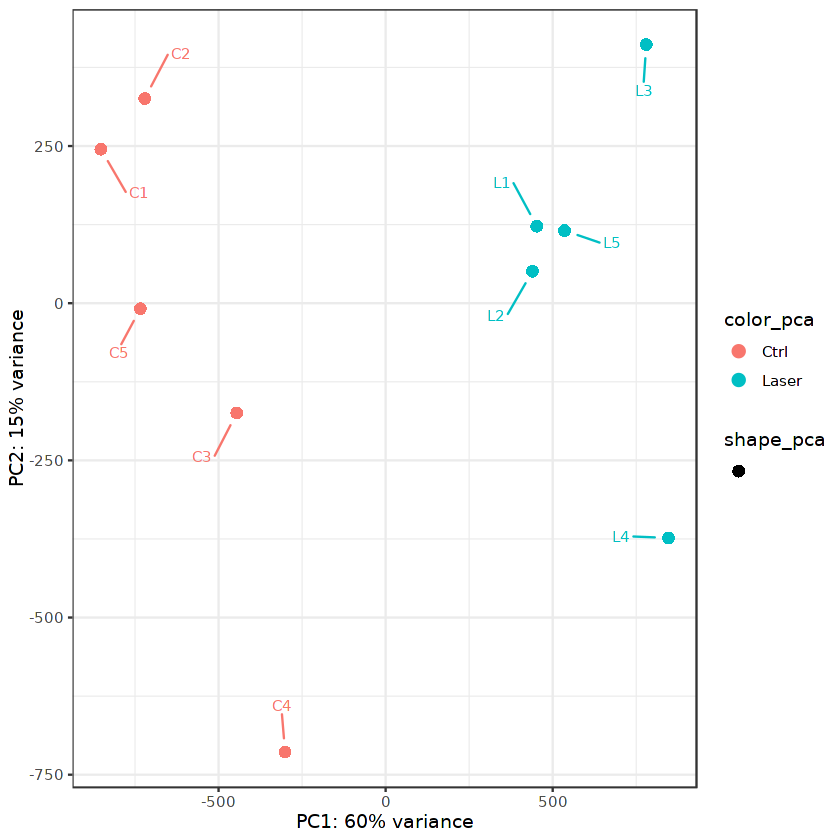

In [ ]:
# PCA / sample QC on the iIQ (imputed, log) intensity matrix
iIQ_mat <- combined_data_iIQ %>%
  dplyr::select(all_of(iIQ_sample_columns)) %>%
  as.matrix()
rownames(iIQ_mat) <- combined_data_iIQ$PG.Genes
colnames(iIQ_mat) <- gsub("^iIQ ", "", colnames(iIQ_mat))

# keep only complete-observation proteins for PCA
iIQ_mat_complete <- iIQ_mat[complete.cases(iIQ_mat), ]
dim(iIQ_mat_complete)

# order sample_meta to match matrix column order
sample_meta_ord <- sample_meta[match(colnames(iIQ_mat_complete), sample_meta$`Short Name`), ]

dir.create("QC", showWarnings = FALSE)

pca_plot <- PCA(iIQ_mat_complete,
    color_pca    = sample_meta_ord$Group,
    label_pca    = sample_meta_ord$`Short Name`,
    save_plot    = "yes",
    name_of_plot = "QC/PCA_Laser_vs_Ctrl")

# PCA() only saves a PDF - also save a 300dpi PNG
ggsave("QC/PCA_Laser_vs_Ctrl.png",
       pca_plot, width = 12, height = 12, dpi = 300)

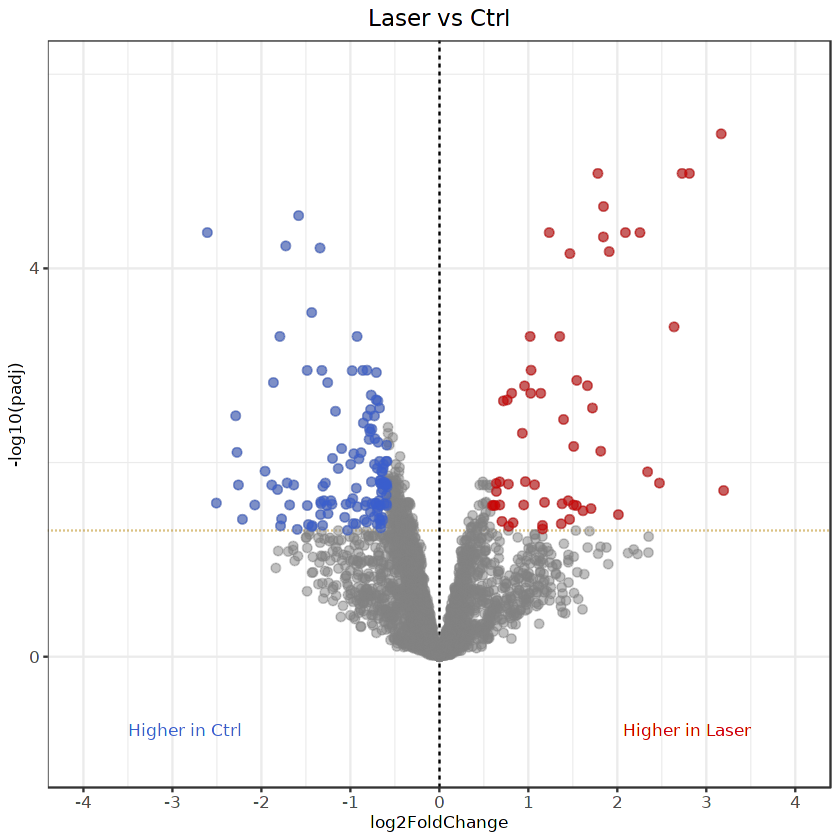

In [7]:
# Volcano plot: Laser vs Ctrl
dir.create("graphs", showWarnings = FALSE)

volcano_plot <- draw_volcano(de_results, title = "Laser vs Ctrl", lfcthres = 0.585)
volcano_plot

ggsave("graphs/Volcano_Laser_vs_Ctrl_lfcthres_0.585.pdf", volcano_plot, width = 8, height = 7)
ggsave("graphs/Volcano_Laser_vs_Ctrl_lfcthres_0.585.png", volcano_plot, width = 8, height = 7, dpi = 300)

In [10]:
# Checkpoint 2: PCA + volcano figures generated
save.image(file = "Analysis_Sph005.RData")

In [ ]:
# GO / Reactome / GSEA enrichment for Laser vs Ctrl
# Human data - no zebrafish->mouse ortholog conversion needed
CONTRASTS <- "Laser_vs_Ctrl"
LFC_THRESHOLDS <- list(lfc0.585 = 0.585, lfc1 = 1.0, lfc2 = 2.0)   # numeric keys only
ORGANISM <- "human"

# ORA: per-contrast, per-threshold significant (padj < 0.05) gene + log2FoldChange table
filtered_results <- list(
  Laser_vs_Ctrl = lapply(LFC_THRESHOLDS, function(thresh) {
    de_results %>%
      filter(padj < 0.05, abs(log2FoldChange) > thresh) %>%
      dplyr::select(gene, log2FoldChange)
  })
)

# GSEA: ranked results per contrast, restricted to padj < 0.05 significant genes
results_list <- list(Laser_vs_Ctrl = de_results)

run_ORA_loop(filtered_results, contrasts = CONTRASTS, thresholds = LFC_THRESHOLDS, org = ORGANISM)
run_GSEA_loop(results_list, contrasts = CONTRASTS, thresholds = LFC_THRESHOLDS, organism = ORGANISM,
              pval_deg = 0.05)

Starting GSEA analysis...
Total analyses: 1 <c3><97> 5 <c3><97> 3 = 15 


=== GSEA for contrast: Laser_vs_Ctrl ===

--- Threshold: lfc0.585 ---
  <e2><86><92> BP ... # A tibble: 1 x 3
  total_genes upregulated downregulated
        <int>       <int>         <int>
1         184          57           127
  Ranked gene list: 184 genes
  Detected ID type: SYMBOL 


'select()' returned 1:1 mapping between keys and columns

Warning message in bitr(names(gene_list), fromType = key_type, toType = "ENTREZID", :
"3.26% of input gene IDs are fail to map..."


  Mapped: 178 genes to ENTREZID


using 'fgsea' for GSEA analysis, please cite Korotkevich et al (2019).


preparing geneSet collections...

GSEA analysis...

leading edge analysis...

done...

'select()' returned 1:1 mapping between keys and columns



  <e2><9c><93> GSEA completed: BP - 25 pathways, 15 plotted <e2><86><92> pathway_analysis/GSEA/lfc0.585/Laser_vs_Ctrl/GO/BP 
  <e2><86><92> MF ... # A tibble: 1 x 3
  total_genes upregulated downregulated
        <int>       <int>         <int>
1         184          57           127
  Ranked gene list: 184 genes
  Detected ID type: SYMBOL 


...

  <e2><9c><97> No GSEA enrichment found for CC 
  <e2><86><92> reactome ... # A tibble: 1 x 3
  total_genes upregulated downregulated
        <int>       <int>         <int>
1          17          10             7
  Ranked gene list: 17 genes
  Detected ID type: SYMBOL 


'select()' returned 1:1 mapping between keys and columns

using 'fgsea' for GSEA analysis, please cite Korotkevich et al (2019).


preparing geneSet collections...

GSEA analysis...

no term enriched under specific pvalueCutoff...



  <e2><9c><97> No GSEA enrichment found for reactome 
  <e2><86><92> msigdb ... # A tibble: 1 x 3
  total_genes upregulated downregulated
        <int>       <int>         <int>
1          17          10             7
  Ranked gene list: 17 genes
  Detected ID type: SYMBOL 


using 'fgsea' for GSEA analysis, please cite Korotkevich et al (2019).


preparing geneSet collections...

GSEA analysis...

no term enriched under specific pvalueCutoff...



  <e2><9c><97> No GSEA enrichment found for msigdb 

<e2><9c><93> Completed all GSEA analyses for Laser_vs_Ctrl 

<e2><9c><93><e2><9c><93><e2><9c><93> All GSEA analyses completed <e2><9c><93><e2><9c><93><e2><9c><93>


In [1]:
# Restore analysis state from checkpoint (fresh kernel session)
source("reusable_functions/source_all.R")
load("Analysis_Sph005.RData")
ls()

✓ viz_functions.R loaded: PCA(), draw_volcano()



Attaching package: ‘dplyr’




The following objects are masked from ‘package:stats’:

    filter, lag




The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




clusterProfiler v4.18.4 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

T Wu, E Hu, S Xu, M Chen, P Guo, Z Dai, T Feng, L Zhou, W Tang, L Zhan,
X Fu, S Liu, X Bo, and G Yu. clusterProfiler 4.0: A universal
enrichment tool for interpreting omics data. The Innovation. 2021,
2(3):100141



...


Attaching package: ‘MatrixGenerics’




The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges, rowRanks,
    rowSdDiffs, rowSds, rowSums2, rowTabulates, rowVarDiffs, rowVars,
    rowWeightedMads, rowWeightedMeans, rowWeightedMedians,
    rowWeightedSds, rowWeig

The following object is masked from ‘package:Biobase’:

    rowMedians




✓ Loaded utils_functions.R
✓ sc_functions.R loaded
  Clustering QC  : compute_clustering_qc(), plot_clustering_qc()
  Annotation     : annotate_celltypes_enrichr()
  DE selection   : compute_data_characteristics(), recommend_de_method()
  DE dispatcher  : run_de_per_celltype()
  DE methods     : run_pseudobulk_limma(), run_limmatrend_cov(),
                   run_limmavoom_cov(), run_edgeR_cov(),
                   run_mast_cov(), run_wilcox_raw()
  LIANA          : run_liana_zebrafish(), run_liana_loop(), plot_liana_dotplot()
  SC enrichment  : run_ORA_loop_sc(), run_GSEA_loop_sc()
✓ All Mercader Lab reusable functions loaded.
  Bulk:        PCA(), draw_volcano(), make_gct(), process_venn_sets()
  Enrichment:  ORA_function(), GSEA_function(), run_ORA_loop(), run_GSEA_loop()
  Orthology:   convert_zf_to_mouse_alliance(), convert_zf_to_human_alliance()
  Single-cell: run_liana_zebrafish(), run_liana_loop(), plot_liana_dotplot(),
               pseudobulk_de(), run_ORA_loop_sc(), run_GSE

[1] "DEG_numbers"                      "GSEA_function"                   
 [3] "ORA_function"                     "PCA"                             
 [5] "annotate_celltypes_enrichr"       "base_dir"                        
 [7] "columns_to_select"                "combined_data"                   
 [9] "combined_data_iIQ"                "compute_clustering_qc"           
[11] "compute_data_characteristics"     "convert_zf_to_human_alliance"    
[13] "convert_zf_to_mouse_alliance"     "de_results"                      
[15] "differential_proteins_Laser_Ctrl" "draw_volcano"                    
[17] "export_table"                     "iIQ_mat"                         
[19] "iIQ_mat_complete"                 "iIQ_sample_columns"              
[21] "iIQ_stat_columns"                 "make_gct"                        
[23] "pca_plot"                         "plot_clustering_qc"              
[25] "plot_liana_dotplot"               "process_venn_sets"               
[27] "protein_columns"                  "pseudobulk_de"                   
[29] "recommend_de_method"              "run_GSEA_loop"                   
[31] "run_GSEA_loop_sc"                 "run_ORA_loop"                    
[33] "run_ORA_loop_sc"                  "run_de_per_celltype"             
[35] "run_edgeR_cov"                    "run_liana_loop"                  
[37] "run_liana_zebrafish"              "run_limmatrend_cov"              
[39] "run_limmavoom_cov"                "run_mast_cov"                    
[41] "run_pseudobulk_limma"             "run_wilcox_raw"                  
[43] "sample_meta"                      "sample_meta_ord"                 
[45] "top20"                            "volcano_plot"                    
[47] "volcano_top20_plot"

In [ ]:
# Excel export: protein identifiers/names + iIQ-only quantification and DE stats
dir.create("tables", showWarnings = FALSE)

export_table <- combined_data_iIQ %>%
  dplyr::select(-`iIQ AND iSN Persistent Signif Laser - Ctrl`) %>%  # cross-method column, not iIQ-only
  arrange(`iIQ EB_adjpVal Laser - Ctrl`)

writexl::write_xlsx(export_table, "tables/DE_results_iIQ_Laser_vs_Ctrl.xlsx")

dim(export_table)
colnames(export_table)

[1] 4080   24

[1] "Leading_Protein"                    "PG.ProteinGroups"                  
 [3] "Leading_Gene"                       "PG.ProteinAccessions"              
 [5] "PG.Genes"                           "PG.Organisms"                      
 [7] "PG.ProteinDescriptions"             "iIQ C1"                            
 [9] "iIQ C2"                             "iIQ C3"                            
[11] "iIQ C4"                             "iIQ C5"                            
[13] "iIQ L1"                             "iIQ L2"                            
[15] "iIQ L3"                             "iIQ L4"                            
[17] "iIQ L5"                             "iIQ log2FC Laser - Ctrl"           
[19] "iIQ EB_stat Laser - Ctrl"           "iIQ EB_pVal Laser - Ctrl"          
[21] "iIQ EB_adjpVal Laser - Ctrl"        "iIQ Signif Laser - Ctrl"           
[23] "iIQ Proportion Signif Laser - Ctrl" "iIQ Persistent Signif Laser - Ctrl"

In [2]:
# DEP_summary: counts of differential/upregulated/downregulated proteins (padj < 0.05)
# at increasing |log2FC| effect-size thresholds
DEP_summary <- tibble(LFC_threshold = c(0, 0.585, 1, 2)) %>%
  rowwise() %>%
  mutate(
    Differential  = sum(de_results$padj < 0.05 & abs(de_results$log2FoldChange) > LFC_threshold, na.rm = TRUE),
    Upregulated   = sum(de_results$padj < 0.05 & de_results$log2FoldChange >  LFC_threshold, na.rm = TRUE),
    Downregulated = sum(de_results$padj < 0.05 & de_results$log2FoldChange < -LFC_threshold, na.rm = TRUE)
  ) %>%
  ungroup()

dir.create("tables", showWarnings = FALSE)
write.csv(DEP_summary, "tables/DEP_summary.csv", row.names = FALSE)

DEP_summary

LFC_threshold,Differential,Upregulated,Downregulated
<dbl>,<int>,<int>,<int>
0.000,405,85,320
0.585,184,57,127
1.000,86,39,47
2.000,17,10,7


In [5]:
# Check ranges to confirm draw_volcano()'s internal capping (|lfc|>7, padj<1e-100) is a no-op here
range(de_results$log2FoldChange, na.rm = TRUE)
range(de_results$padj, na.rm = TRUE)

[1] -2.607815  3.195053

[1] 4.111396e-06 9.992268e-01

gene,log2FoldChange,padj
<chr>,<dbl>,<dbl>
NDUFB1,3.1673043,4.111396e-06
F5,1.7817891,1.050613e-05
BMP1,2.7277444,1.050613e-05
ROR1,2.8104685,1.050613e-05
GDF15,1.8446469,2.304476e-05
MTHFR,-1.5815277,2.859750e-05
NPC1,2.2543987,4.276569e-05
CA2,-2.6078153,4.276569e-05
COX5A,1.2345681,4.276569e-05


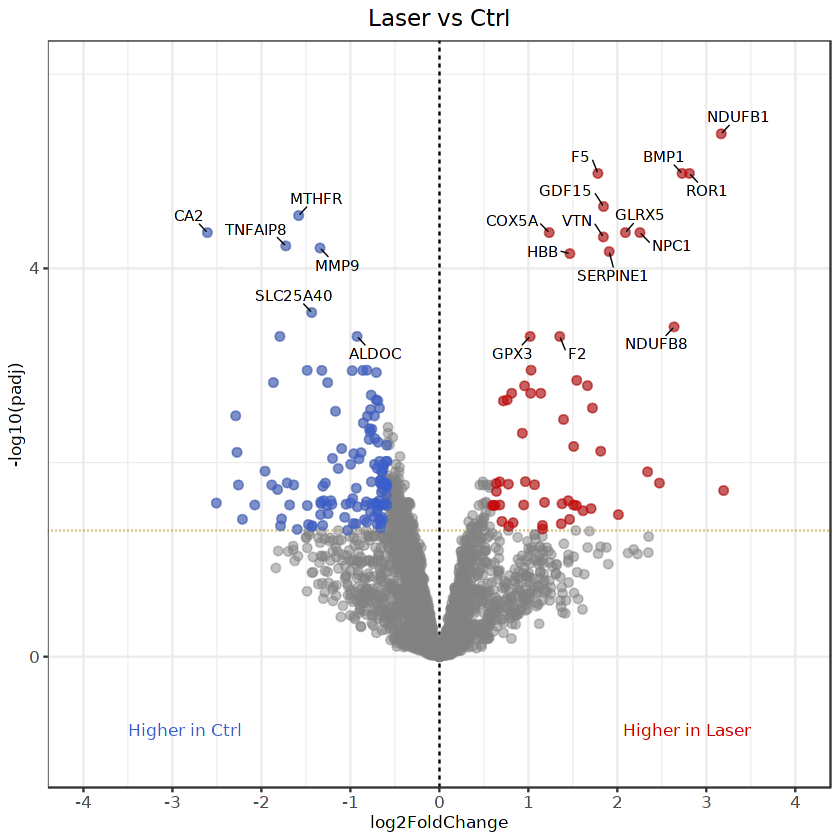

In [ ]:
# Volcano plot with top 20 differential proteins labeled
# Must cross BOTH volcano thresholds (padj < 0.05 AND |log2FC| > 0.585, matching draw_volcano's
# own lfcthres = 0.585 coloring), ranked by smallest padj among those
top20 <- de_results %>%
  filter(padj < 0.05, abs(log2FoldChange) > 0.585) %>%
  arrange(padj) %>%
  slice_head(n = 20)

volcano_top20_plot <- volcano_plot +
  ggrepel::geom_text_repel(data = top20,
                           aes(x = log2FoldChange, y = -log10(padj), label = gene),
                           size = 3, max.overlaps = 100, box.padding = 0.4,
                           min.segment.length = 0, segment.size = 0.3)
volcano_top20_plot

ggsave("graphs/Volcano_Laser_vs_Ctrl_top20_labeled_lfcthres_0.585.pdf", volcano_top20_plot, width = 9, height = 8)
ggsave("graphs/Volcano_Laser_vs_Ctrl_top20_labeled_lfcthres_0.585.png", volcano_top20_plot, width = 9, height = 8, dpi = 300)

top20 %>% dplyr::select(gene, log2FoldChange, padj)

In [ ]:
# Final checkpoint: DE table, figures, enrichment, Excel export, DEP_summary, top-20 volcano all complete
save.image(file = "Analysis_Sph005.RData")


In [ ]:
load("Analysis_Sph005.RData")